In [1]:
import tkinter as tk
from tkinter import ttk, filedialog, messagebox
import os
import sys
import pickle
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [3]:
df = pd.read_csv("rtl_power_modeling_dataset2.csv")
print(df.head())
print(df.columns)


   cycle_id benchmark    block instruction  toggle_count  hamming_dist  \
0         1      sort    Fetch         ALU             5             2   
1         2     crc32      LSU         NOP            35            21   
2         3    matmul  Execute         NOP            14             4   
3         4     nbody      LSU         ALU            57            19   
4         5       aes    Fetch         ALU            12            10   

   control_activity  data_bus_activity  stall  static_power_mW  \
0                 0              3.203      0          0.40158   
1                 0             12.469      0          0.87511   
2                 0              2.015      0          0.73455   
3                 0              8.039      0          0.84875   
4                 0              4.529      0          0.41661   

   dynamic_power_mW  total_power_mW  total_check  
0           0.03416         0.43574      0.43574  
1           1.16404         2.03915      2.03915  
2    

In [4]:
print(df.columns)


Index(['cycle_id', 'benchmark', 'block', 'instruction', 'toggle_count',
       'hamming_dist', 'control_activity', 'data_bus_activity', 'stall',
       'static_power_mW', 'dynamic_power_mW', 'total_power_mW', 'total_check'],
      dtype='object')


In [5]:
# separate input features and target column
X = df.drop(["total_power_mW", "cycle_id", "total_check"], axis=1, errors="ignore")
y = df["total_power_mW"]

# check dataset sizes
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (200000, 10)
y shape: (200000,)


In [6]:
# app.py
# GUI for RTL total_power_mW prediction using a trained model.pkl
# Left: inputs (auto-generated from training.csv)
# Right: outputs (predicted total_power_mW + status)

import os
import sys
import json
import pickle
import traceback
import numpy as np
import pandas as pd
from typing import Dict, List, Any
import tkinter as tk
from tkinter import ttk, messagebox, filedialog

# ------------ CONFIG (adjust paths if needed) ------------
TRAINING_CSV = "rtl_power_modeling_dataset2.csv"             # must contain the columns used for training
MODEL_PKL    = "decision_tree_power_model_1.pkl"                # trained model (pipeline or regressor)
TARGET_COL   = "total_power_mW"
ID_COLS      = ["cycle_id"]
EXCLUDE_COLS = ["total_check"]              # columns to ignore for inputs
LOW_CARDINALITY_THRESHOLD = 20            # max unique values to treat numeric as categorical
# ---------------------------------------------------------

In [7]:
def is_boolean_series(s):
    if s.dtype == bool:
        return True
    vals = pd.Series(s.dropna().unique()).astype(str).str.lower().tolist()
    return set(vals).issubset({"0", "1", "true", "false", "yes", "no"}) or \
           set(s.dropna().unique()).issubset({0, 1})


def load_model(path):
    with open(path, "rb") as f:
        return pickle.load(f)


def robust_to_numeric(x):
    try:
        return float(x)
    except:
        return np.nan


def detect_schema(df, target_col, id_cols):

    remove_cols = []
    for c in [target_col] + list(id_cols) + EXCLUDE_COLS:
        if c in df.columns:
            remove_cols.append(c)

    feature_cols = []
    for c in df.columns:
        if c not in remove_cols:
            feature_cols.append(c)

    schema = []

    for col in feature_cols:
        s = df[col]

        if is_boolean_series(s):
            default = str(int(pd.to_numeric(s, errors="coerce").fillna(0).median()))
            schema.append({
                "name": col,
                "type": "bool",
                "values": ["0", "1"],
                "default": default
            })

        elif s.dtype == object or s.nunique(dropna=True) <= LOW_CARDINALITY_THRESHOLD:
            cats = sorted(pd.Series(s.dropna().unique()).astype(str).tolist())
            if len(cats) == 0:
                cats = [""]
            schema.append({
                "name": col,
                "type": "category",
                "values": cats,
                "default": cats[0]
            })

        else:
            med = pd.to_numeric(s, errors="coerce").median()
            if np.isnan(med):
                default = ""
            else:
                default = str(round(float(med), 6))

            schema.append({
                "name": col,
                "type": "number",
                "values": None,
                "default": default
            })

    return schema, feature_cols


def build_encoder_reference(df_train, features):

    df_feat = df_train[features].copy()

    for col in df_feat.columns:
        if is_boolean_series(df_feat[col]):
            df_feat[col] = pd.to_numeric(df_feat[col], errors="coerce").fillna(0).astype(int)

    enc = pd.get_dummies(df_feat)
    enc = enc.iloc[:1].copy()
    enc.iloc[0] = 0

    return enc


def encode_single_row(raw_row, encoder_ref):

    enc = pd.get_dummies(raw_row)
    aligned = encoder_ref.copy()

    for col in enc.columns:
        if col in aligned.columns:
            aligned[col] = enc[col].values[0]

    return aligned


class PowerApp(tk.Tk):

    def __init__(self):
        super().__init__()

        self.title("RTL Power Prediction")
        self.geometry("1200x700")
        self.minsize(1000, 600)

        if not os.path.exists(TRAINING_CSV):
            messagebox.showerror("Error", "Training file not found")
            sys.exit(1)

        self.df_train = pd.read_csv(TRAINING_CSV)

        if TARGET_COL not in self.df_train.columns:
            messagebox.showerror("Error", "Target column missing in dataset")
            sys.exit(1)

        self.schema, self.feature_cols = detect_schema(
            self.df_train, TARGET_COL, ID_COLS
        )

        self.encoder_ref = build_encoder_reference(
            self.df_train, self.feature_cols
        )

        self.build_layout()

    # ---------------- GUI ----------------

    def build_layout(self):

        notebook = ttk.Notebook(self)
        notebook.pack(fill=tk.BOTH, expand=True)

        pred_tab = ttk.Frame(notebook)
        train_tab = ttk.Frame(notebook)

        notebook.add(pred_tab, text="Prediction")
        notebook.add(train_tab, text="Training")
        # -------- NEW TABS (Added) --------
        analysis_tab = ttk.Frame(notebook)
        viz_tab = ttk.Frame(notebook)
        compare_tab = ttk.Frame(notebook)

        notebook.add(analysis_tab, text="Dataset Analysis")
        notebook.add(viz_tab, text="Training Visualization")
        notebook.add(compare_tab, text="Model Comparison")

        # Build new tabs
        self.build_analysis_tab(analysis_tab)
        self.build_visualization_tab(viz_tab)
        self.build_comparison_tab(compare_tab)

        paned = ttk.PanedWindow(pred_tab, orient=tk.HORIZONTAL)
        paned.pack(fill=tk.BOTH, expand=True, padx=10, pady=10)

        left_frame = ttk.Frame(paned)
        paned.add(left_frame, weight=1)

        canvas = tk.Canvas(left_frame)
        scroll = ttk.Scrollbar(left_frame, orient="vertical", command=canvas.yview)
        self.form_frame = ttk.Frame(canvas)

        self.form_frame.bind("<Configure>",
            lambda e: canvas.configure(scrollregion=canvas.bbox("all")))

        canvas.create_window((0, 0), window=self.form_frame, anchor="nw")
        canvas.configure(yscrollcommand=scroll.set)

        canvas.pack(side="left", fill="both", expand=True)
        scroll.pack(side="right", fill="y")

        ttk.Label(self.form_frame, text="Input Features",
                  font=("Segoe UI", 12, "bold")) \
            .grid(row=0, column=0, columnspan=2, sticky="w")

        ttk.Label(self.form_frame, text="Select Trained Model") \
            .grid(row=1, column=0, sticky="w", pady=(8, 2))

        self.predict_model_choice = tk.StringVar(value="SVM")

        ttk.Combobox(self.form_frame,
                     textvariable=self.predict_model_choice,
                     values=["SVM", "KNN", "Neural Network"],
                     state="readonly",
                     width=25) \
            .grid(row=1, column=1, pady=(8, 2))

        self.input_vars = {}
        row = 2

        for item in self.schema:
            name = item["name"]

            ttk.Label(self.form_frame, text=name) \
                .grid(row=row, column=0, sticky="w", padx=4, pady=2)

            if item["type"] == "bool":
                var = tk.StringVar(value=item["default"])
                box = ttk.Combobox(self.form_frame,
                                   textvariable=var,
                                   values=["0", "1"],
                                   state="readonly")
                box.grid(row=row, column=1, padx=4)

            elif item["type"] == "category":
                var = tk.StringVar(value=item["default"])
                box = ttk.Combobox(self.form_frame,
                                   textvariable=var,
                                   values=item["values"],
                                   state="readonly",
                                   width=30)
                box.grid(row=row, column=1, padx=4)

            else:
                var = tk.StringVar(value=item["default"])
                ent = ttk.Entry(self.form_frame, textvariable=var)
                ent.grid(row=row, column=1, padx=4)

            self.input_vars[name] = var
            row += 1

        btns = ttk.Frame(self.form_frame)
        btns.grid(row=row, column=0, columnspan=2, pady=10)

        ttk.Button(btns, text="Predict", command=self.predict).pack(side="left", padx=5)
        ttk.Button(btns, text="Reset", command=self.reset_inputs).pack(side="left", padx=5)

        right_frame = ttk.Frame(paned)
        paned.add(right_frame, weight=1)

        ttk.Label(right_frame, text="Prediction Output",
                  font=("Segoe UI", 12, "bold")).pack(anchor="w")

        self.output_box = tk.Text(right_frame, height=25)
        self.output_box.pack(fill="both", expand=True, pady=8)

        # -------- Training Tab --------

        ttk.Label(train_tab, text="Model Training",
                  font=("Segoe UI", 12, "bold")).pack(pady=10)

        train_frame = ttk.Frame(train_tab)
        train_frame.pack(pady=10)

        self.train_file = tk.StringVar(value="No file selected")

        def browse():
            path = filedialog.askopenfilename(filetypes=[("CSV Files", "*.csv")])
            if path:
                self.train_file.set(path)

        ttk.Button(train_frame, text="Select Dataset", command=browse)\
            .grid(row=0, column=0, padx=5, pady=5)

        ttk.Label(train_frame, textvariable=self.train_file, width=50)\
            .grid(row=0, column=1, padx=5)

        ttk.Label(train_frame, text="Select Model:")\
            .grid(row=1, column=0, pady=10)

        self.model_choice = tk.StringVar(value="SVM")

        ttk.Combobox(train_frame,
                     textvariable=self.model_choice,
                     values=["SVM", "KNN", "Neural Network"],
                     state="readonly", width=20)\
            .grid(row=1, column=1)

        ttk.Button(train_frame, text="Train Model",
                   command=self.train_model_from_gui)\
            .grid(row=2, column=0, columnspan=2, pady=15)

        self.train_status = tk.StringVar(value="Not trained")
        ttk.Label(train_tab, textvariable=self.train_status).pack(pady=5)

        self.progress = ttk.Progressbar(train_tab, mode="determinate", length=300)
        self.progress.pack(pady=8)

    # ---------------- Prediction ----------------

    def gather_single_row(self):
        row = {}
        for k, v in self.input_vars.items():
            row[k] = v.get()
        return pd.DataFrame([row])

    def predict(self):
        self.output_box.delete("1.0", tk.END)

        try:
            df_row = self.gather_single_row()

            choice = self.predict_model_choice.get()

            if choice == "SVM":
                model = joblib.load("svm_model.pkl")
            elif choice == "KNN":
                model = joblib.load("knn_model.pkl")
            else:
                model = joblib.load("nn_model.pkl")

            yhat = model.predict(df_row)[0]
            self.output_box.insert(tk.END, f"Predicted total_power_mW: {yhat:.6f}")

        except Exception as e:
            self.output_box.insert(tk.END, str(e))

    def reset_inputs(self):
        for name, var in self.input_vars.items():
            info = next((c for c in self.schema if c["name"] == name), None)
            if info:
                var.set(info["default"])
        self.output_box.delete("1.0", tk.END)

    # ---------------- Training ----------------

    def train_model_from_gui(self):
        try:
            path = self.train_file.get()
            if not path or path == "No file selected":
                messagebox.showerror("Error", "Select dataset file")
                return

            df = pd.read_csv(path)

            X = df.drop(["total_power_mW", "cycle_id", "total_check"], axis=1, errors="ignore")
            y = df["total_power_mW"]

            cat_cols = ["benchmark", "block", "instruction"]
            num_cols = [c for c in X.columns if c not in cat_cols]

            prep = ColumnTransformer([
                ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                ("num", StandardScaler(), num_cols)
            ])

            choice = self.model_choice.get()

            if choice == "SVM":
                model = SVR()
                default_name = "svm_model.pkl"
            elif choice == "KNN":
                model = KNeighborsRegressor(n_neighbors=5)
                default_name = "knn_model.pkl"
            else:
                model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300)
                default_name = "nn_model.pkl"

            pipe = Pipeline([
                ("preprocess", prep),
                ("model", model)
            ])

            Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

            self.train_status.set("Training in progress...")
            self.progress["value"] = 0
            self.update()

            for i in range(50):
                self.progress["value"] += 1
                self.update()
                self.after(15)

            pipe.fit(Xtr, ytr)

            for i in range(50, 100):
                self.progress["value"] += 1
                self.update()
                self.after(15)

            preds = pipe.predict(Xte)
            score = r2_score(yte, preds)

            save_path = filedialog.asksaveasfilename(
                defaultextension=".pkl",
                filetypes=[("Model Files", "*.pkl")],
                initialfile=default_name
            )

            if save_path:
                joblib.dump(pipe, save_path)
                self.train_status.set(f"Training done! R² = {score:.4f}")
                messagebox.showinfo("Success", f"Model saved at:\n{save_path}")
            else:
                self.train_status.set(f"Training done! R² = {score:.4f} (not saved)")

        except Exception as e:
            messagebox.showerror("Training Error", str(e))

                # ============================================================
                # 1️⃣ DATASET ANALYSIS TAB
                # ============================================================

    def build_analysis_tab(self, parent):

        frame = ttk.Frame(parent)
        frame.pack(fill="both", expand=True, padx=10, pady=10)

        ttk.Button(frame,
                   text="Run Dataset Analysis",
                   command=self.run_dataset_analysis).pack(pady=10)

        self.analysis_text = tk.Text(frame, height=15)
        self.analysis_text.pack(fill="both", expand=True)


    def run_dataset_analysis(self):

        df = self.df_train

        self.analysis_text.delete("1.0", tk.END)

        info = (
            f"Rows: {df.shape[0]}\n"
            f"Columns: {df.shape[1]}\n\n"
            f"Missing Values:\n{df.isnull().sum()}\n\n"
            f"Duplicate Rows: {df.duplicated().sum()}\n"
        )

        self.analysis_text.insert(tk.END, info)

        # Correlation Matrix
        corr = df.corr(numeric_only=True)
        plt.figure(figsize=(8,6))
        plt.imshow(corr, aspect='auto')
        plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
        plt.yticks(range(len(corr.columns)), corr.columns)
        plt.colorbar()
        plt.title("Correlation Matrix")
        plt.tight_layout()
        plt.show()

        # Target Distribution
        if TARGET_COL in df.columns:
            plt.figure()
            df[TARGET_COL].hist(bins=30)
            plt.title("Target Distribution")
            plt.xlabel(TARGET_COL)
            plt.ylabel("Frequency")
            plt.show()


        # ================= Visualization =================

    def build_visualization_tab(self, parent):
        frame = ttk.Frame(parent)
        frame.pack(fill="both", expand=True, padx=10, pady=10)

        ttk.Button(frame,
                   text="Show Training Graphs",
                   command=self.show_training_graphs).pack(pady=10)

    def show_training_graphs(self):

        df = self.df_train.copy()

        drop_cols = ["cycle_id", "total_check"]
        drop_cols = [c for c in drop_cols if c in df.columns]

        X = df.drop([TARGET_COL] + drop_cols, axis=1)
        y = df[TARGET_COL]

        X = pd.get_dummies(X)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

        model = MLPRegressor(max_iter=200)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        plt.figure()
        plt.scatter(y_test, y_pred)
        plt.title("Actual vs Predicted")
        plt.show()
        from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg

    def build_visualization_tab(self, parent):

        self.viz_frame = ttk.Frame(parent)
        self.viz_frame.pack(fill="both", expand=True, padx=10, pady=10)

        ttk.Button(self.viz_frame,
                   text="Show Training Graphs",
                   command=self.show_training_graphs).pack(pady=10)

    def show_training_graphs(self):

        for widget in self.viz_frame.winfo_children():
            if isinstance(widget, tk.Canvas):
                widget.destroy()

        df = self.df_train.copy()

        drop_cols = ["cycle_id", "total_check"]
        drop_cols = [c for c in drop_cols if c in df.columns]

        X = df.drop([TARGET_COL] + drop_cols, axis=1)
        y = df[TARGET_COL]

        X = pd.get_dummies(X)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

        model = MLPRegressor(max_iter=200)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        fig, ax = plt.subplots(figsize=(5,4))
        ax.scatter(y_test, y_pred)
        ax.set_title("Actual vs Predicted")
        ax.set_xlabel("Actual")
        ax.set_ylabel("Predicted")

        canvas = FigureCanvasTkAgg(fig, master=self.viz_frame)
        canvas.draw()
        canvas.get_tk_widget().pack(fill="both", expand=True)


    # ================= Model Comparison =================

        def build_comparison_tab(self, parent):

        self.compare_frame = ttk.Frame(parent)
        self.compare_frame.pack(fill="both", expand=True, padx=10, pady=10)

        ttk.Button(self.compare_frame,
                   text="Compare Models",
                   command=self.compare_models).pack(pady=10)

    def compare_models(self):

        for widget in self.compare_frame.winfo_children():
            if isinstance(widget, tk.Canvas):
                widget.destroy()

        df = self.df_train.copy()

        drop_cols = ["cycle_id", "total_check"]
        drop_cols = [c for c in drop_cols if c in df.columns]

        X = df.drop([TARGET_COL] + drop_cols, axis=1)
        y = df[TARGET_COL]

        X = pd.get_dummies(X)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

        models = {
            "DT": DecisionTreeRegressor(),
            "RF": RandomForestRegressor(),
            "SVM": SVR(),
            "NN": MLPRegressor(max_iter=200)
        }

        r2_scores = []

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            r2_scores.append(r2_score(y_test, y_pred))

        fig, ax = plt.subplots(figsize=(5,4))
        ax.bar(models.keys(), r2_scores)
        ax.set_title("R2 Comparison")

        canvas = FigureCanvasTkAgg(fig, master=self.compare_frame)
        canvas.draw()
        canvas.get_tk_widget().pack(fill="both", expand=True)

IndentationError: expected an indented block after function definition on line 532 (3741178636.py, line 534)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_7324\678167034.py:85: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  enc.iloc[0] = 0
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7324\678167034.py:85: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  enc.iloc[0] = 0
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7324\678167034.py:85: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  enc.iloc[0] = 0
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7324\678167034.py:85: FutureWarning: Setting an item o

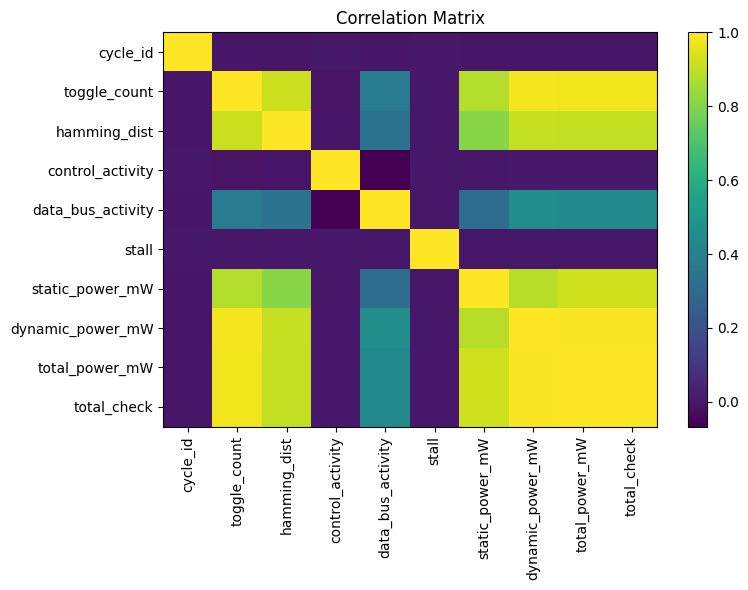

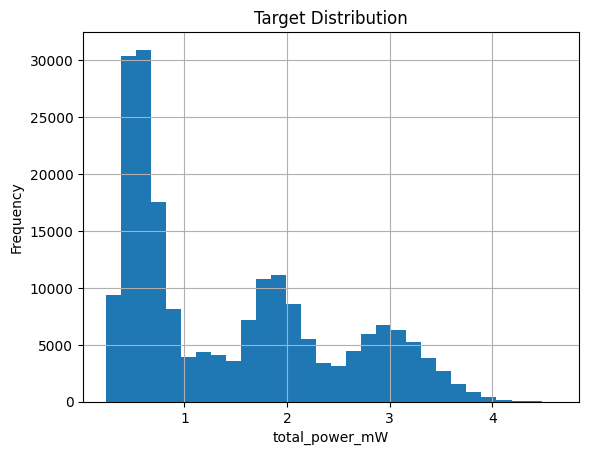

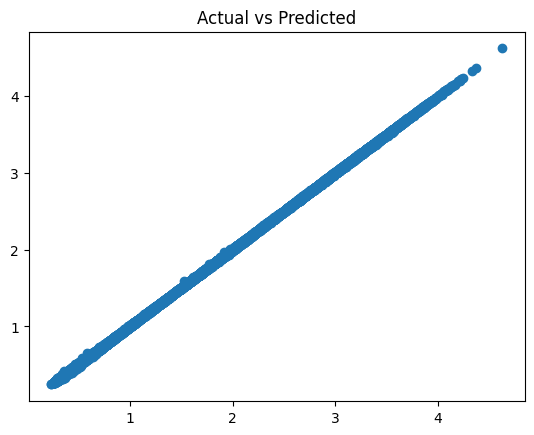

In [ ]:
if __name__ == "__main__":
    app = PowerApp()
    app.mainloop()
